# Modelado: predicción de `mora`
Entradas: `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv` (generados en `02_limpieza.ipynb`).

**Plan**
1. Modelos base: regresión logística, random forest y gradient boosting.
2. Validación cruzada estratificada (5 folds) **solo con train**.
3. Dos escenarios: **con** y **sin** `tasa_interes` (por la posible fuga de información detectada en el EDA).
4. Evaluación en test: AUC-ROC, PR-AUC, precisión, recall, F1 y balanced accuracy.
5. Ajuste del umbral de decisión con predicciones fuera de muestra del train.
6. Interpretación: odds ratios e importancia por permutación.

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

SEMILLA = 42
ESCENARIO_FINAL = "SIN_TASA"   # escenario usado en las secciones 6 y 7: "CON_TASA" o "SIN_TASA"

## 1. Carga de datos

In [2]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze("columns")
y_test = pd.read_csv("y_test.csv").squeeze("columns")

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporción de mora -> train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))
print("Columnas:", list(X_train.columns))

X_train: (6719, 25) | X_test: (1680, 25)
Proporción de mora -> train: 0.7043 | test: 0.7042
Columnas: ['edad', 'num_cuotas', 'tasa_interes', 'ingreso_log', 'plazo_dias', 'vivienda_FAMILIAR', 'vivienda_PROPIA', 'nivel_educ_TECNICA', 'nivel_educ_UNIVERSITARIA', 'genero_M', 'estado_civil_CONVIVIENTE', 'estado_civil_DIVORCIADO_VIUDO', 'estado_civil_SOLTERO', 'sector_economico_COMERCIO', 'sector_economico_CONSTRUCCION', 'sector_economico_EDUCATIVO', 'sector_economico_MANUFACTURA', 'sector_economico_OTROS', 'sector_economico_SALUD', 'sector_economico_SERVICIOS', 'sector_economico_TRANSPORTES', 'forma_pago_MENSUAL', 'forma_pago_QUINCENAL', 'forma_pago_SEMANAL', 'exp_otras_entidades']


## 2. Definición de modelos
`mora = 1` es la clase mayoritaria (≈70 %). Se usa `class_weight="balanced"` en logística y random forest.  
`HistGradientBoostingClassifier` no se pondera: su AUC no depende del umbral y el umbral se ajusta en la sección 5.

In [3]:
modelos = {
    "Regresion logistica": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA),
    "Random forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=10, class_weight="balanced",
        n_jobs=-1, random_state=SEMILLA),
    "Gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_depth=4, max_iter=300, l2_regularization=1.0,
        random_state=SEMILLA),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

escenarios = {
    "CON_TASA": list(X_train.columns),
    "SIN_TASA": [c for c in X_train.columns if c != "tasa_interes"],
}
{k: len(v) for k, v in escenarios.items()}

{'CON_TASA': 25, 'SIN_TASA': 24}

## 3. Funciones de evaluación

In [4]:
def metricas(y_true, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    return {
        "AUC_ROC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced_Acc": balanced_accuracy_score(y_true, pred),
        "Precision_mora": precision_score(y_true, pred, zero_division=0),
        "Recall_mora": recall_score(y_true, pred),
        "Recall_no_mora": recall_score(y_true, pred, pos_label=0),
        "F1_mora": f1_score(y_true, pred),
    }

def correr_escenario(nombre, columnas):
    Xtr, Xte = X_train[columnas], X_test[columnas]
    filas, probas = [], {}
    for nom, base in modelos.items():
        mod = clone(base)
        auc_cv = cross_val_score(mod, Xtr, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
        mod.fit(Xtr, y_train)
        p = mod.predict_proba(Xte)[:, 1]
        probas[nom] = p
        fila = {"Escenario": nombre, "Modelo": nom,
                "AUC_CV_media": auc_cv.mean(), "AUC_CV_std": auc_cv.std()}
        fila.update(metricas(y_test, p))
        filas.append(fila)
    return pd.DataFrame(filas), probas

## 4. Resultados por escenario (umbral = 0.5)

In [5]:
resultados, probas_por_esc = [], {}
for nombre, cols in escenarios.items():
    res, probas = correr_escenario(nombre, cols)
    resultados.append(res)
    probas_por_esc[nombre] = probas

resultados = pd.concat(resultados, ignore_index=True)
resultados

c:\Users\asus\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\asus\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\asus\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\asus\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1024, in __init__
    self._execute_child(args, executable, preexec_fn, close

,Escenario,Modelo,AUC_CV_media,AUC_CV_std,AUC_ROC,PR_AUC,Accuracy,Balanced_Acc,Precision_mora,Recall_mora,Recall_no_mora,F1_mora
0,CON_TASA,Regresion logistica,0.8853,0.0054,0.8690,0.9318,0.7935,0.7874,0.8936,0.8022,0.7726,0.8454
1,CON_TASA,Random forest,0.8748,0.0051,0.8665,0.9320,0.7976,0.7886,0.8921,0.8107,0.7666,0.8494
2,CON_TASA,Gradient boosting,0.8854,0.0040,0.8703,0.9304,0.8196,0.7658,0.8537,0.8977,0.6338,0.8752
3,SIN_TASA,Regresion logistica,0.6428,0.0081,0.6518,0.8030,0.6202,0.6113,0.7859,0.6331,0.5895,0.7013
4,SIN_TASA,Random forest,0.6498,0.0080,0.6752,0.8253,0.6518,0.6186,0.7826,0.6999,0.5372,0.7390
5,SIN_TASA,Gradient boosting,0.6618,0.0052,0.6848,0.8330,0.7107,0.5408,0.7224,0.9569,0.1247,0.8233


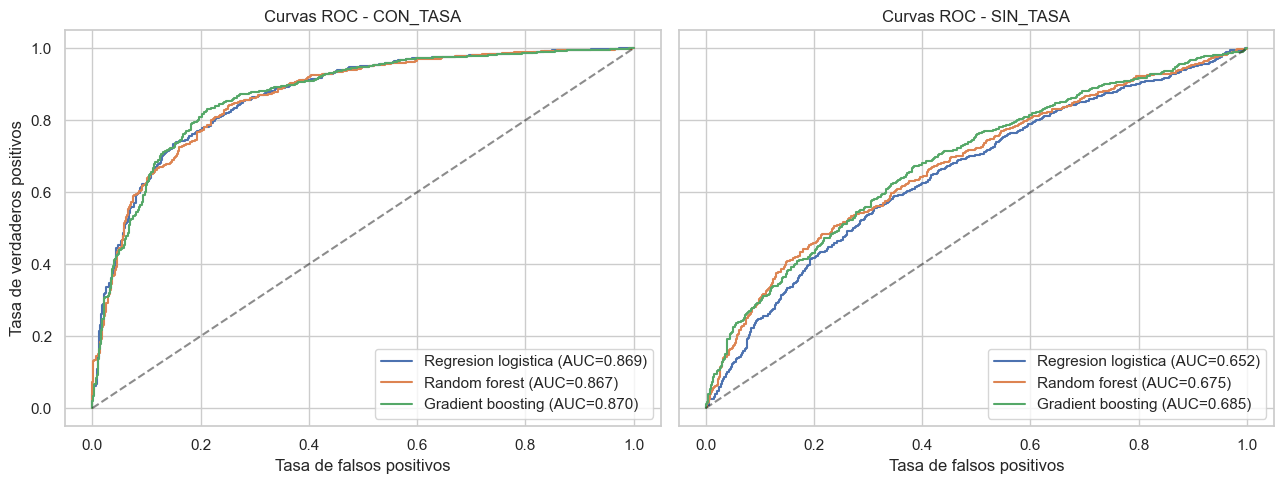

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (nombre, probas) in zip(axes, probas_por_esc.items()):
    for nom, p in probas.items():
        fpr, tpr, _ = roc_curve(y_test, p)
        auc = roc_auc_score(y_test, p)
        ax.plot(fpr, tpr, label=f"{nom} (AUC={auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_title(f"Curvas ROC - {nombre}")
    ax.set_xlabel("Tasa de falsos positivos")
    ax.legend(loc="lower right")
axes[0].set_ylabel("Tasa de verdaderos positivos")
plt.tight_layout()
plt.show()

In [7]:
# Efecto de incluir tasa_interes sobre el AUC en test
comp = resultados.pivot(index="Modelo", columns="Escenario", values="AUC_ROC")
comp["Diferencia (CON - SIN)"] = comp["CON_TASA"] - comp["SIN_TASA"]
comp

Escenario,CON_TASA,SIN_TASA,Diferencia (CON - SIN)
Modelo,,,
Gradient boosting,0.8703,0.6848,0.1855
Random forest,0.8665,0.6752,0.1913
Regresion logistica,0.8690,0.6518,0.2171


## 5. Ajuste del umbral
Con el desbalance, el umbral 0.5 no suele ser el mejor. Se elige con predicciones **fuera de muestra del train** (validación cruzada), maximizando el *balanced accuracy* (equivale al índice de Youden), y luego se aplica una sola vez al test.

Escenario final: SIN_TASA
Mejor modelo por AUC en CV: Gradient boosting
Umbral óptimo (CV en train): 0.66


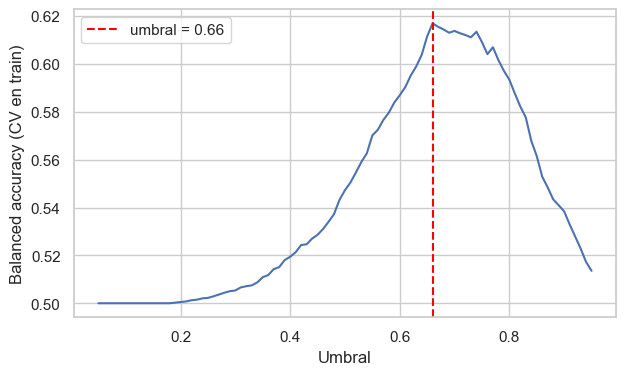

In [8]:
cols_final = escenarios[ESCENARIO_FINAL]
Xtr_f, Xte_f = X_train[cols_final], X_test[cols_final]

# Mejor modelo del escenario final según AUC en validación cruzada (no en test)
tabla_esc = resultados[resultados["Escenario"] == ESCENARIO_FINAL].set_index("Modelo")
mejor_nombre = tabla_esc["AUC_CV_media"].idxmax()
print("Escenario final:", ESCENARIO_FINAL)
print("Mejor modelo por AUC en CV:", mejor_nombre)

mejor = clone(modelos[mejor_nombre])
oof = cross_val_predict(mejor, Xtr_f, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

umbrales = np.linspace(0.05, 0.95, 91)
bal = [balanced_accuracy_score(y_train, (oof >= u).astype(int)) for u in umbrales]
umbral_opt = umbrales[int(np.argmax(bal))]
print(f"Umbral óptimo (CV en train): {umbral_opt:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(umbrales, bal)
plt.axvline(umbral_opt, color="red", ls="--", label=f"umbral = {umbral_opt:.2f}")
plt.xlabel("Umbral")
plt.ylabel("Balanced accuracy (CV en train)")
plt.legend()
plt.show()

In [9]:
mejor.fit(Xtr_f, y_train)
p_test = mejor.predict_proba(Xte_f)[:, 1]

comparacion = pd.DataFrame({
    "umbral 0.5": metricas(y_test, p_test, 0.5),
    f"umbral {umbral_opt:.2f}": metricas(y_test, p_test, umbral_opt),
}).T
comparacion

,AUC_ROC,PR_AUC,Accuracy,Balanced_Acc,Precision_mora,Recall_mora,Recall_no_mora,F1_mora
umbral 0.5,0.6848,0.8330,0.7107,0.5408,0.7224,0.9569,0.1247,0.8233
umbral 0.66,0.6848,0.8330,0.6732,0.6256,0.7825,0.7422,0.5091,0.7618


              precision    recall  f1-score   support

 no mora (0)      0.453     0.509     0.480       497
    mora (1)      0.783     0.742     0.762      1183

    accuracy                          0.673      1680
   macro avg      0.618     0.626     0.621      1680
weighted avg      0.685     0.673     0.678      1680



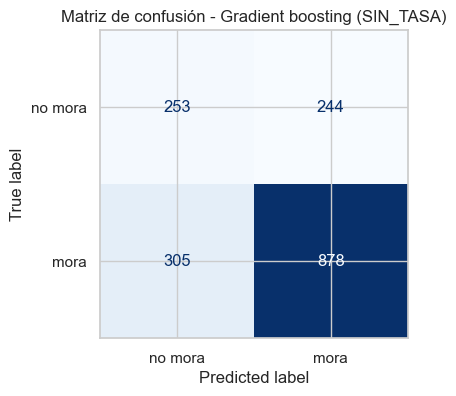

In [10]:
pred_opt = (p_test >= umbral_opt).astype(int)
print(classification_report(y_test, pred_opt, target_names=["no mora (0)", "mora (1)"], digits=3))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_opt), display_labels=["no mora", "mora"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión - {mejor_nombre} ({ESCENARIO_FINAL})")
plt.show()

## 6. Interpretación: regresión logística (odds ratios)

In [11]:
logit = clone(modelos["Regresion logistica"]).fit(Xtr_f, y_train)
coef = pd.Series(logit.coef_[0], index=cols_final)
odds = pd.DataFrame({"coeficiente": coef, "odds_ratio": np.exp(coef)}).sort_values("coeficiente", key=abs, ascending=False)
odds

,coeficiente,odds_ratio
vivienda_PROPIA,-0.7358,0.4791
vivienda_FAMILIAR,-0.6500,0.5220
nivel_educ_UNIVERSITARIA,-0.5028,0.6049
forma_pago_MENSUAL,0.3751,1.4552
ingreso_log,-0.3579,0.6992
forma_pago_QUINCENAL,0.2469,1.2801
sector_economico_OTROS,0.2430,1.2750
forma_pago_SEMANAL,0.2023,1.2243
sector_economico_MANUFACTURA,-0.1702,0.8435
sector_economico_CONSTRUCCION,0.1571,1.1701


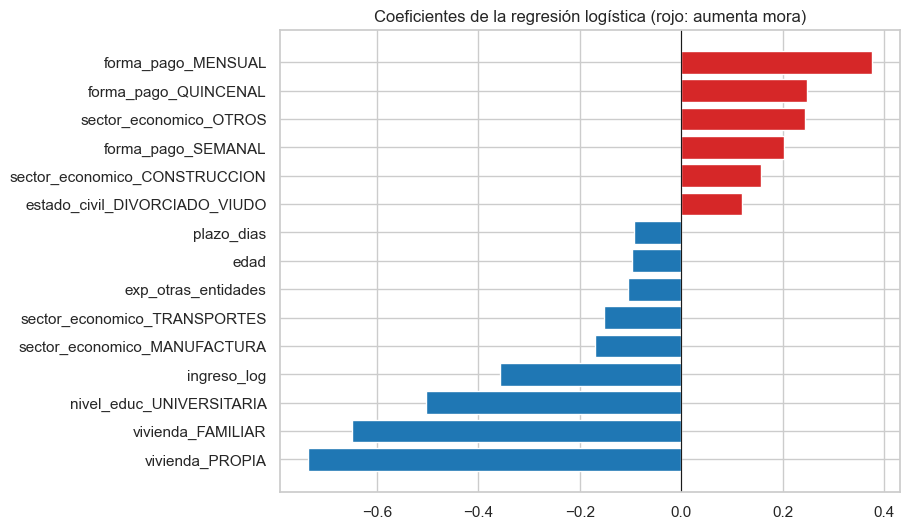

In [12]:
top = odds.head(15).sort_values("coeficiente")
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["coeficiente"], color=np.where(top["coeficiente"] > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="k", lw=0.8)
plt.title("Coeficientes de la regresión logística (rojo: aumenta mora)")
plt.show()

## 7. Importancia por permutación (modelo seleccionado, en test)

,importancia_media,desv
ingreso_log,0.1299,0.0183
edad,0.0591,0.0115
nivel_educ_UNIVERSITARIA,0.0223,0.0048
vivienda_PROPIA,0.0070,0.0025
vivienda_FAMILIAR,0.0028,0.0018
sector_economico_MANUFACTURA,0.0014,0.0016
nivel_educ_TECNICA,0.0012,0.0011
forma_pago_MENSUAL,0.0008,0.0004
estado_civil_SOLTERO,0.0003,0.0015
sector_economico_CONSTRUCCION,0.0003,0.0011


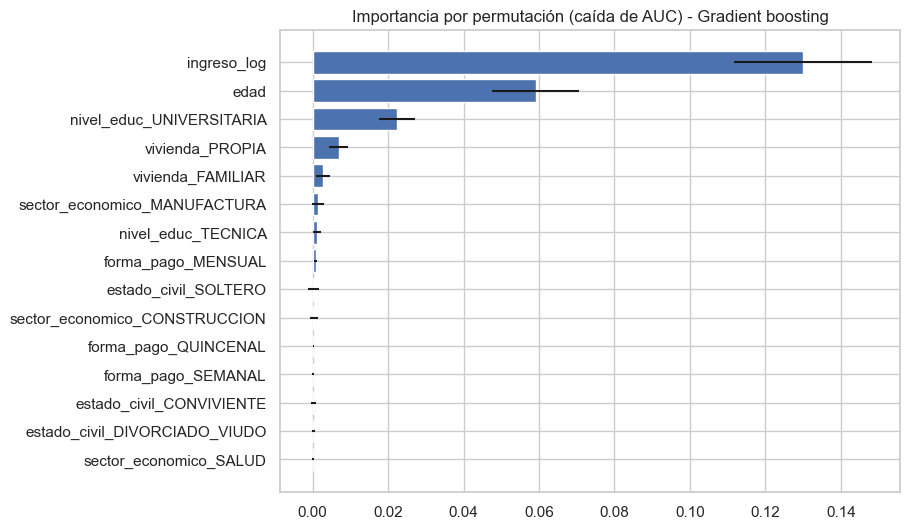

In [13]:
perm = permutation_importance(mejor, Xte_f, y_test, scoring="roc_auc",
                              n_repeats=15, random_state=SEMILLA, n_jobs=-1)
imp = pd.DataFrame({"importancia_media": perm.importances_mean,
                    "desv": perm.importances_std}, index=cols_final).sort_values("importancia_media", ascending=False)
display(imp.head(15))

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["importancia_media"], xerr=top["desv"])
plt.title(f"Importancia por permutación (caída de AUC) - {mejor_nombre}")
plt.show()

## 8. Guardar resultados

In [14]:
resultados.to_csv("resultados_modelos.csv", index=False)
comparacion.to_csv("resultados_umbral.csv")
print("Guardado: resultados_modelos.csv, resultados_umbral.csv")

Guardado: resultados_modelos.csv, resultados_umbral.csv


## Resumen para el siguiente paso
Copia las salidas de las secciones 4, 5, 6 y 7. Con eso redacto la interpretación de resultados (para tu tarea) y, si quieres, hacemos ajuste de hiperparámetros, calibración de probabilidades o un modelo tipo *scorecard*.